# Exploratory Data Analysis (EDA) of the Wine Quality Dataset

**Course:** Statistics for Machine Learning and Data Science  
**Assignment:** 01  
**Student Name:** Abdul Ghani  
**UIN:** 01/241A056  
**Dataset:** Wine Quality — Red Wine  
**Source:** UCI Machine Learning Repository

## Objective
Perform dataset understanding, data inspection, visualization, descriptive statistics, preprocessing, sampling, and draw evidence-based conclusions. In Colab, open this notebook (File → Upload notebook), keep `winequality-red.csv` in the Files panel, then choose Runtime → Run all before submission.

## Import Libraries and Load Dataset

This notebook uses the **red Wine Quality dataset** (`winequality-red.csv`). In Google Colab, upload this notebook and keep the CSV in the Files panel, as shown in your screenshot. The file is read locally, so this step does not need to download the dataset from the internet.

The `quality` column is the target. Since it is numeric, this notebook treats the task primarily as **regression**. The same analysis can be adapted for the white wine file by changing `DATASET_FILE` below to `winequality-white.csv`.

Dataset source: [UCI Wine Quality Dataset](https://archive.ics.uci.edu/dataset/186/wine+quality).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

%matplotlib inline
sns.set_theme(style="whitegrid")

# Choose the red wine CSV already uploaded in the Colab Files panel.
# To analyse white wine instead, change this to: "winequality-white.csv"
DATASET_FILE = "winequality-red.csv"

# Search the common locations used by Google Colab and Jupyter.
possible_paths = [Path("/content") / DATASET_FILE, Path(DATASET_FILE), Path("/mnt/data") / DATASET_FILE]
dataset_path = next((p for p in possible_paths if p.exists()), None)

# If the file is not found, prompt for a local upload in Colab.
if dataset_path is None:
    try:
        from google.colab import files
        print(f"Could not find {DATASET_FILE}. Please select it from your computer.")
        uploaded = files.upload()
        dataset_path = Path("/content") / DATASET_FILE
        if not dataset_path.exists() and DATASET_FILE in uploaded:
            dataset_path = Path(DATASET_FILE)
    except ImportError:
        raise FileNotFoundError(f"{DATASET_FILE} was not found. Place it beside the notebook or in /content.")

if dataset_path is None or not dataset_path.exists():
    raise FileNotFoundError(f"{DATASET_FILE} was not found. Make sure the correct CSV is uploaded.")

# UCI Wine Quality CSV files are semicolon-separated, not comma-separated.
df = pd.read_csv(dataset_path, sep=";")
print("Dataset loaded successfully from:", dataset_path)
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully from: /content/winequality-red.csv
Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


# Part A: Dataset Understanding

## 1. Brief Description
The Wine Quality dataset contains laboratory-based physicochemical measurements of red wine, such as acidity, residual sugar, chlorides, sulfur dioxide, density, pH, sulphates, and alcohol. Each record also has a `quality` score assigned by sensory evaluation.

## 2. Dataset Details

In [2]:
print("Dataset source: UCI Machine Learning Repository — Red Wine Quality")
print("Number of samples:", df.shape[0])
print("Number of columns (including target):", df.shape[1])
print("Number of input features:", df.shape[1] - 1)
print("Target variable: quality")
print("Problem type: Regression (quality score is numeric)")
print("Columns:", df.columns.tolist())

Dataset source: UCI Machine Learning Repository — Red Wine Quality
Number of samples: 1599
Number of columns (including target): 12
Number of input features: 11
Target variable: quality
Problem type: Regression (quality score is numeric)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


# Part B: Data Inspection

Inspect the first and last records, structure, data types, missing values, duplicate records, and descriptive statistics.

In [3]:
# First five records
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
# Last five records
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [5]:
# Dataset structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
# Data types for each column
df.dtypes

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


In [7]:
# Missing values in each column
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [8]:
# Number of exact duplicate rows
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 240


In [9]:
# Descriptive statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


## Observations

The cells above display the dataset's actual shape, data types, missing-value counts, duplicate count, and summary statistics. Use those outputs to write your final observations. Duplicate rows should be investigated before removal because repeated measurements may be genuine or may reflect duplicate records.

# Part C: Data Visualisation

Each visualization is followed by a short interpretation. The observations should be checked against the plots generated when the notebook is run.

## 1. Histogram — Alcohol

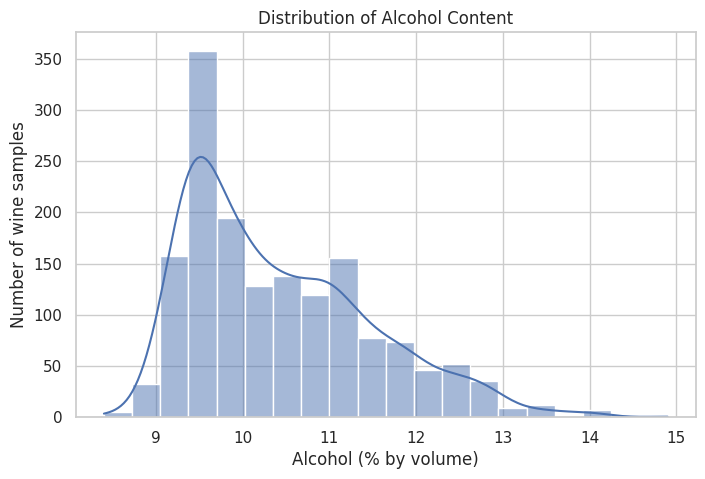

Alcohol skewness: 0.861
Alcohol mean: 10.423
Alcohol median: 10.2


In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="alcohol", bins=20, kde=True)
plt.title("Distribution of Alcohol Content")
plt.xlabel("Alcohol (% by volume)")
plt.ylabel("Number of wine samples")
plt.show()

print("Alcohol skewness:", round(df["alcohol"].skew(), 3))
print("Alcohol mean:", round(df["alcohol"].mean(), 3))
print("Alcohol median:", round(df["alcohol"].median(), 3))

### Observations
1. Alcohol values are concentrated around the lower-to-middle part of the observed range, with fewer wines at very high alcohol levels.
2. The histogram is not perfectly symmetric; the shape should be checked against the displayed distribution and skewness value.
3. The histogram helps identify the typical alcohol content and whether unusually high or low values are present.

## 2. Box Plot — Alcohol

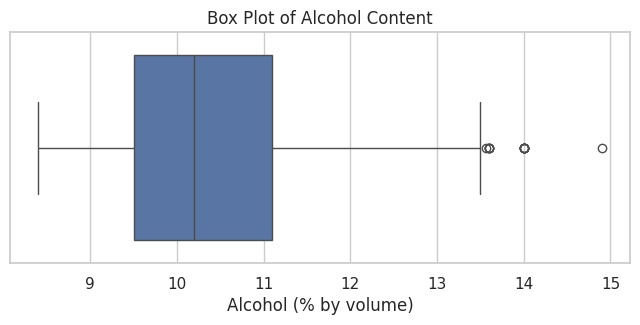

IQR lower fence: 7.1
IQR upper fence: 13.5
Potential outliers: 13


In [11]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["alcohol"])
plt.title("Box Plot of Alcohol Content")
plt.xlabel("Alcohol (% by volume)")
plt.show()

q1, q3 = df["alcohol"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("IQR lower fence:", round(lower, 3))
print("IQR upper fence:", round(upper, 3))
print("Potential outliers:", int(((df["alcohol"] < lower) | (df["alcohol"] > upper)).sum()))

### Observations
1. The line inside the box represents the median alcohol content, while the box covers the middle 50% of observations (IQR).
2. Points beyond the whiskers are potential outliers according to the 1.5 × IQR rule; they are not automatically errors.
3. The spread indicates that alcohol content varies across wine samples.

## 3. Scatter Plot — Alcohol vs Quality

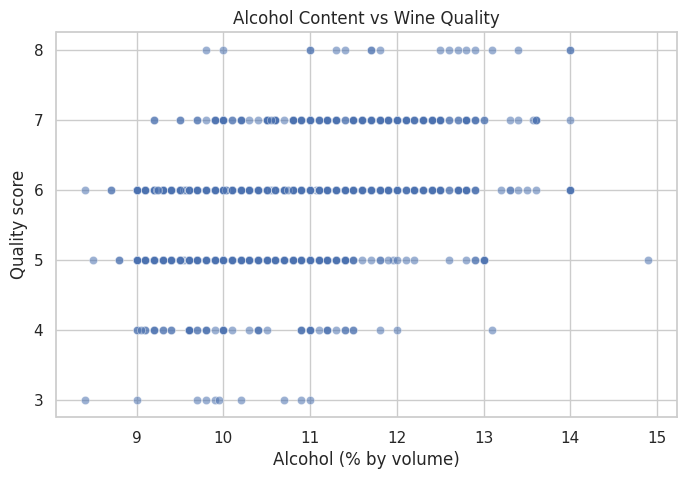

Correlation (alcohol, quality): 0.476


In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="alcohol", y="quality", alpha=0.55)
plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Alcohol (% by volume)")
plt.ylabel("Quality score")
plt.show()

print("Correlation (alcohol, quality):", round(df["alcohol"].corr(df["quality"]), 3))

### Observations
1. The plot allows the relationship between alcohol content and quality score to be assessed; higher alcohol content often tends to occur with higher quality scores in this dataset.
2. Quality is recorded as discrete integer scores, so points form horizontal bands rather than a continuous vertical spread.
3. There is substantial overlap between quality groups, meaning alcohol alone cannot fully explain a wine's quality score.

## 4. Pair Plot — Selected Variables

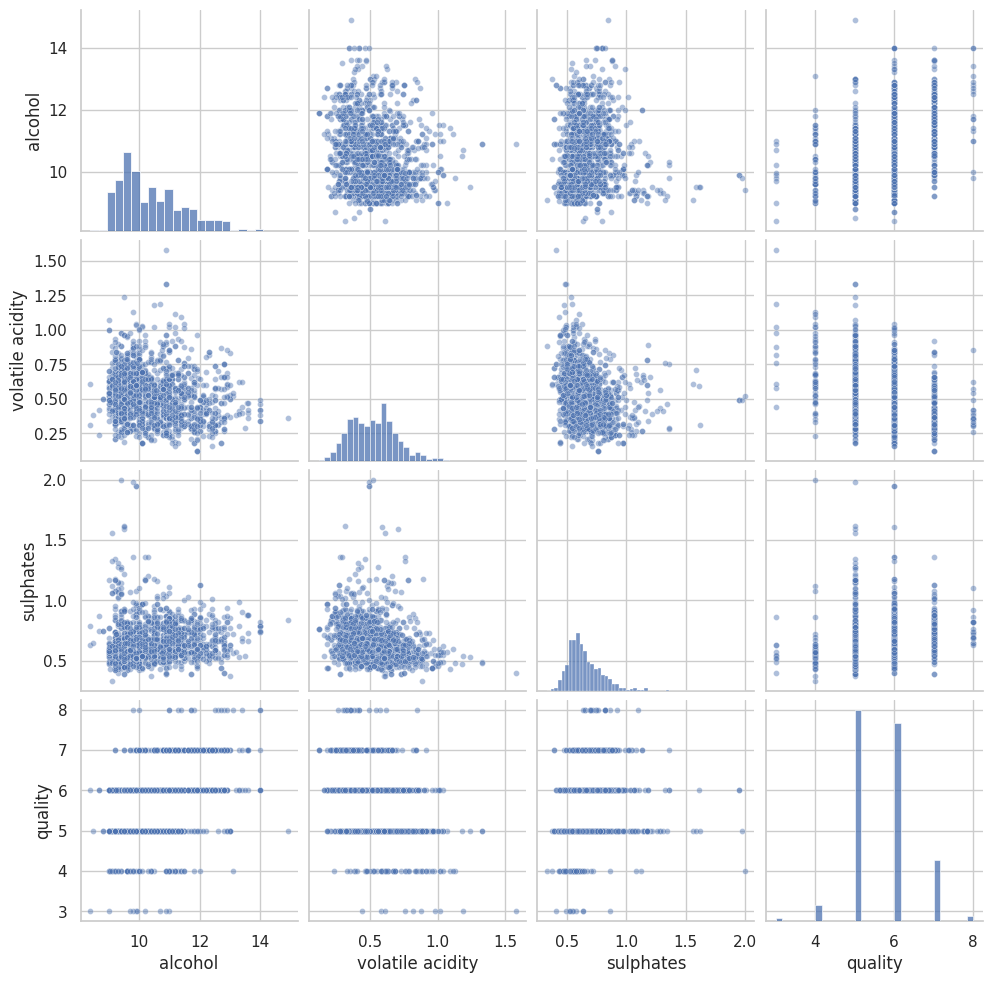

In [13]:
selected_features = ["alcohol", "volatile acidity", "sulphates", "quality"]
sns.pairplot(df[selected_features], diag_kind="hist", plot_kws={"alpha": 0.45, "s": 18})
plt.show()

### Observations
1. The diagonal histograms show the distributions of alcohol, volatile acidity, sulphates, and quality.
2. The scatter panels help compare pairs of variables; alcohol generally shows a positive association with quality, while volatile acidity tends to show a negative association.
3. The panels also show considerable overlap and spread, indicating that several variables should be considered together rather than relying on one feature.

## 5. Correlation Heatmap

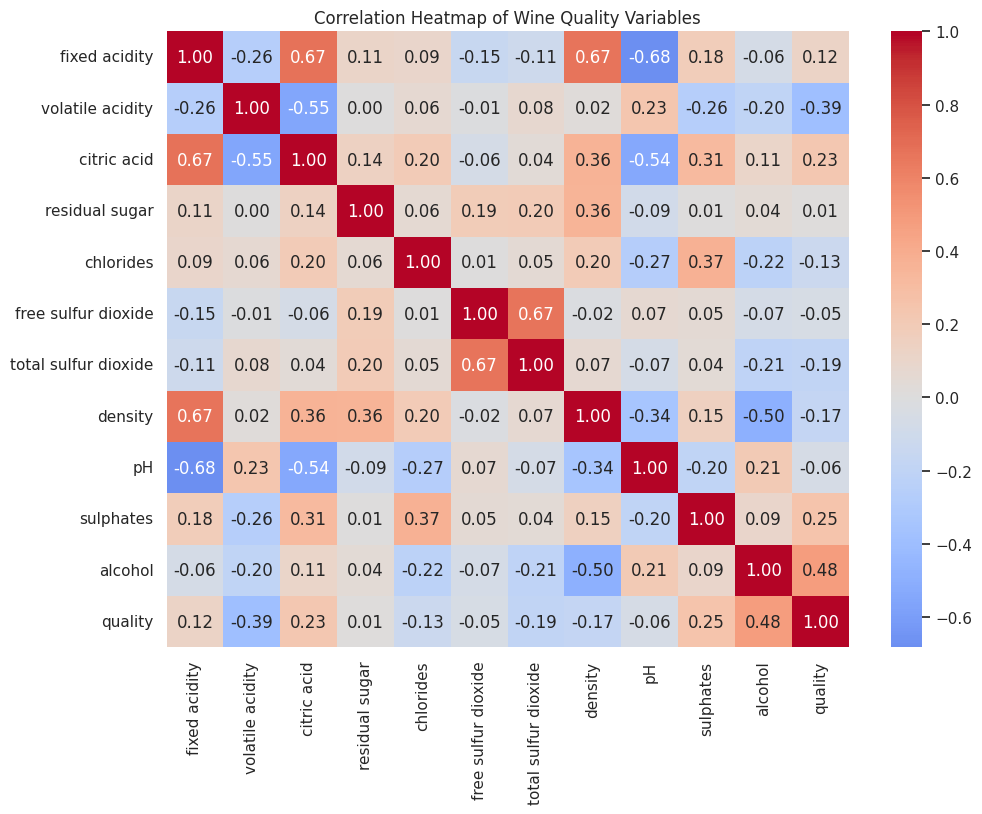

Correlations with quality, sorted:
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


In [14]:
plt.figure(figsize=(11, 8))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap of Wine Quality Variables")
plt.show()

print("Correlations with quality, sorted:")
print(corr["quality"].drop("quality").sort_values(ascending=False))

### Observations
1. Alcohol generally has a positive correlation with quality, while volatile acidity generally has a negative correlation with quality.
2. Sulphates and citric acid typically show positive but weaker associations with quality than alcohol.
3. Correlation measures linear association, not causation; weak correlations do not prove that a feature is unimportant for every machine-learning model.

# Part D: Descriptive Statistics

The following cell computes the required statistics for the `alcohol` feature. The same method can be applied to other numeric columns.

In [15]:
feature = df["alcohol"]
stats = pd.DataFrame({
    "Statistic": [
        "Mean", "Median", "Mode", "Variance", "Standard Deviation",
        "Range", "Interquartile Range (IQR)", "Skewness", "Kurtosis"
    ],
    "Value": [
        feature.mean(),
        feature.median(),
        ", ".join(map(str, feature.mode().round(3).tolist())),
        feature.var(),
        feature.std(),
        feature.max() - feature.min(),
        feature.quantile(0.75) - feature.quantile(0.25),
        feature.skew(),
        feature.kurt()
    ]
})
stats

,Statistic,Value
0,Mean,10.422983
1,Median,10.2
2,Mode,9.5
3,Variance,1.135647
4,Standard Deviation,1.065668
5,Range,6.5
6,Interquartile Range (IQR),1.6
7,Skewness,0.860829
8,Kurtosis,0.200029


## Interpretation of Statistics

- **Mean:** Average alcohol content.
- **Median:** Middle alcohol measurement after sorting.
- **Mode:** Most frequently occurring value or values.
- **Variance:** Average squared spread around the mean (sample variance in pandas).
- **Standard deviation:** Typical spread around the mean, in the original measurement units.
- **Range:** Maximum minus minimum.
- **IQR:** Third quartile minus first quartile; spread of the middle 50% of observations.
- **Skewness:** Indicates distribution asymmetry; positive values indicate a longer right tail and negative values a longer left tail.
- **Kurtosis:** Pandas reports excess kurtosis; values near zero are similar to a normal distribution in this measure.

# Part E: Data Preprocessing

## 1. Missing Values

Check missing values first. Numeric columns are imputed with their medians only if missing values exist. This is more robust to extreme values than mean imputation.

In [16]:
missing_before = df.isnull().sum()
print("Missing values before treatment:\n", missing_before)

df_clean = df.copy()
numeric_cols = df_clean.select_dtypes(include=np.number).columns
for col in numeric_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("\nMissing values after treatment:\n", df_clean.isnull().sum())

Missing values before treatment:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Missing values after treatment:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


## 2. Duplicate Records

Exact duplicates are counted and removed in the working copy to prevent repeated rows from disproportionately influencing analysis. Compare the number removed with the earlier inspection output.

In [17]:
duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", duplicates_before)
print("Shape after duplicate handling:", df_clean.shape)

Duplicate rows removed: 240
Shape after duplicate handling: (1359, 12)


## 3. Outlier Inspection

The IQR rule flags potential outliers in numeric columns. Wine chemistry can naturally vary, so this notebook reports potential outliers instead of automatically deleting valid measurements.

In [18]:
outlier_summary = []
for col in df_clean.select_dtypes(include=np.number).columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    outlier_summary.append({"Feature": col, "Potential outliers": int(count),
                            "Lower fence": lower, "Upper fence": upper})
pd.DataFrame(outlier_summary)

,Feature,Potential outliers,Lower fence,Upper fence
0,fixed acidity,41,3.95000,12.35000
1,volatile acidity,19,0.01500,1.01500
2,citric acid,1,-0.42000,0.94000
3,residual sugar,126,0.85000,3.65000
4,chlorides,87,0.03850,0.12250
5,free sulfur dioxide,26,-14.00000,42.00000
6,total sulfur dioxide,45,-39.50000,124.50000
7,density,35,0.99227,1.00115
8,pH,28,2.92500,3.68500
9,sulphates,55,0.28000,1.00000


**Justification:** IQR flags observations for review, not proof of incorrect data. Since no domain evidence is available that these values are errors, potentially valid wine measurements are retained.

## 4. Categorical Encoding

The red wine dataset's physicochemical columns and `quality` target are numeric, so categorical encoding is not required for this dataset. If quality is converted into named categories for a classification task, those categories would need an appropriate encoding.

In [19]:
print("Object/categorical columns:", df_clean.select_dtypes(include=["object", "category"]).columns.tolist())
print("No categorical input columns require encoding in the original red-wine dataset.")

Object/categorical columns: []
No categorical input columns require encoding in the original red-wine dataset.


## 5. Standardisation

Standardise the input features for algorithms that are sensitive to feature scale. Keep the target `quality` separate and do not scale it as part of the input features. Fit the scaler only on training data to avoid data leakage.

In [20]:
X = df_clean.drop(columns=["quality"])
y = df_clean["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Scaled training array shape:", X_train_scaled.shape)
print("Scaled testing array shape:", X_test_scaled.shape)

Training input shape: (1087, 11)
Testing input shape: (272, 11)
Scaled training array shape: (1087, 11)
Scaled testing array shape: (272, 11)


**Justification:** Standardisation transforms each input feature to a comparable scale using training-set means and standard deviations. This is useful for distance-based and gradient-based methods. Tree-based models generally do not require feature scaling.

# Part F: Sampling

Create a 10% simple random sample and a 10% stratified sample. Because `quality` is a numeric score with discrete values, use quality-score groups as strata so the sample better preserves the target distribution. The bins are only for sampling, not a change to the regression target.

In [21]:
# Simple random sample (10%)
random_sample = df_clean.sample(frac=0.10, random_state=42)

# Create quality bins for stratification, keeping the original quality values unchanged.
# qcut with duplicates='drop' handles cases where quantile edges coincide.
quality_strata = pd.qcut(df_clean["quality"], q=min(4, df_clean["quality"].nunique()),
                         duplicates="drop")

stratified_sample, _ = train_test_split(
    df_clean,
    test_size=0.90,
    random_state=42,
    stratify=quality_strata
)

print("Full dataset size:", len(df_clean))
print("Random sample size:", len(random_sample))
print("Stratified sample size:", len(stratified_sample))

Full dataset size: 1359
Random sample size: 136
Stratified sample size: 135


In [22]:
# Compare descriptive statistics for selected variables
comparison = pd.DataFrame({
    "Full dataset mean": df_clean[["alcohol", "volatile acidity", "quality"]].mean(),
    "Random sample mean": random_sample[["alcohol", "volatile acidity", "quality"]].mean(),
    "Stratified sample mean": stratified_sample[["alcohol", "volatile acidity", "quality"]].mean(),
    "Full dataset std": df_clean[["alcohol", "volatile acidity", "quality"]].std(),
    "Random sample std": random_sample[["alcohol", "volatile acidity", "quality"]].std(),
    "Stratified sample std": stratified_sample[["alcohol", "volatile acidity", "quality"]].std()
})
comparison

,Full dataset mean,Random sample mean,Stratified sample mean,Full dataset std,Random sample std,Stratified sample std
alcohol,10.432315,10.332353,10.512222,1.082065,1.004721,1.141753
volatile acidity,0.529478,0.559963,0.542889,0.183031,0.213417,0.198443
quality,5.623252,5.441176,5.622222,0.823578,0.717658,0.854022


In [23]:
print("Full dataset quality distribution:")
print(df_clean["quality"].value_counts(normalize=True).sort_index().round(3))
print("\nRandom sample quality distribution:")
print(random_sample["quality"].value_counts(normalize=True).sort_index().round(3))
print("\nStratified sample quality distribution:")
print(stratified_sample["quality"].value_counts(normalize=True).sort_index().round(3))

Full dataset quality distribution:
quality
3    0.007
4    0.039
5    0.425
6    0.394
7    0.123
8    0.013
Name: proportion, dtype: float64

Random sample quality distribution:
quality
3    0.015
4    0.029
5    0.515
6    0.382
7    0.059
Name: proportion, dtype: float64

Stratified sample quality distribution:
quality
3    0.007
4    0.044
5    0.422
6    0.393
7    0.111
8    0.022
Name: proportion, dtype: float64


## Sampling Observations

Compare the displayed means, standard deviations, and quality distributions. Simple random sampling is easy to apply but may under- or over-represent less common quality scores. Stratified sampling is designed to preserve the distribution of the quality-based strata more consistently. Small differences between sample statistics and full-dataset statistics are expected.

# Part G: Conclusion

The Wine Quality dataset contains physicochemical measurements of red wine samples and an integer quality score. Exploratory analysis using descriptive statistics and five visualisations helps summarise feature distributions, identify potential outliers, and examine relationships between chemical properties and wine quality.

Alcohol generally has a positive association with quality, while volatile acidity generally has a negative association. These relationships are useful signals, but no single feature fully explains the quality score. Missing values and duplicate records should be checked using the notebook outputs. IQR-based outliers are flagged for inspection rather than automatically deleted because extreme chemistry values may be genuine observations.

The dataset is suitable for supervised machine learning, with `quality` as the target. Since quality is an integer score, the task can be framed as either regression or classification depending on the objective. Standardisation is applied to input features for scale-sensitive algorithms; it is fitted only on the training set to avoid data leakage. The sampling comparison checks whether the selected samples preserve the original distribution of quality scores.

**Before submission:** run every cell, inspect the generated outputs, and adjust observations if your outputs differ. Cite the dataset source as the UCI Machine Learning Repository.

# AI Ethical Usage Declaration

I declare that this assignment is my original work. Any Generative AI tools (such as ChatGPT, Gemini, GitHub Copilot, Claude, or similar) were used only to assist with learning, debugging, or improving code readability. I have independently verified all code, analysis, visualisations, interpretations, and conclusions presented in this notebook. Any external resources or AI assistance used have been appropriately acknowledged.